# 06. Deployment and monitoring

**Goal.** Serve the system as a governed API, observe it, and detect drift.

**Playbook steps covered:** 8 (deploy as a governed service), 9 (monitor, detect drift, close the loop)

> Every step below has three parts: a **rationale** (why we do it), the **code** with line-level comments
> (how we do it), and an **evaluation** (how we know it worked). All notebooks run **offline** by default
> (hashing embedder + extractive baseline LLM). Switch to Claude and sentence-transformers with
> `AD_RAG_LLM_BACKEND=anthropic` and `AD_RAG_EMBEDDING_BACKEND=sentence-transformers`.

> The corpus is **synthetic educational content**. Nothing here is clinical guidance.

In [1]:
# ---- Setup: make the notebook runnable from anywhere (GitHub clone, Colab, Docker) ----
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the repo root by walking up until we see configs/config.yaml.
ROOT = Path.cwd()
while not (ROOT / "configs" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.environ["AD_RAG_HOME"] = str(ROOT)          # tell the package where the repo lives

# Fresh environment (e.g. Colab)? Install the package in editable mode first:
#   %pip install -q -e ".[notebooks]"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ad_rag import load_settings, build_pipeline

settings = load_settings()                     # typed config from configs/config.yaml (+ env overrides)
print("repo root :", ROOT)
print("embedder  :", settings.embedding.backend, "| llm backend:", settings.llm.backend)

repo root : /home/claude/alzheimers-llm-rag-agent
embedder  : hashing | llm backend: extractive


### Step 1: Serve the API (in-process) and call every endpoint

**Rationale.** The same FastAPI app that runs in Docker is exercised here in-process with `TestClient`, so we can test the exact HTTP contract (validation, response shape) without opening a port.

**How this step is evaluated.** Health reports index facts; `/ask` returns grounded answers with sources; `/agent` returns a trace; `/feedback` is recorded.

In [2]:
from fastapi.testclient import TestClient
from ad_rag.api import create_app

pipe = build_pipeline(settings)
app = create_app(settings, pipe)
client = TestClient(app).__enter__()               # __enter__ runs the lifespan (startup) hook

print("GET /health        ->", client.get("/health").json())
ans = client.post("/ask", json={"question": "How does chronic kidney disease affect plasma biomarkers?"}).json()
print("\nPOST /ask          -> grounded:", ans["grounded"], "| sources:", [s["source"] for s in ans["sources"]][:2])
ag = client.post("/agent", json={"task": "The assay ratio was 0.72 in a symptomatic adult. Is it above the cutoff?"}).json()
print("POST /agent        -> tools:", ag["tools_used"], "| escalated:", ag["escalated"])
fb = client.post("/feedback", json={"request_id": ans["request_id"], "helpful": True})
print("POST /feedback     ->", fb.json())
print("validation (too-short question) ->", client.post("/ask", json={"question": "hi"}).status_code)

GET /health        -> {'status': 'ok', 'version': '0.1.0', 'chunks_indexed': 52, 'corpus_version': 'e639851bb748', 'embedder': 'hashing-4096', 'llm': 'extractive-baseline'}

POST /ask          -> grounded: True | sources: ['confounders_and_comorbidities.md', 'blood_biomarker_overview.md']
POST /agent        -> tools: ['search_knowledge_base', 'interpret_biomarker'] | escalated: False
POST /feedback     -> {'status': 'recorded'}
validation (too-short question) -> 422


### Step 2: Authentication

**Rationale.** Clinical endpoints must not be open. If `API_KEY` is set, every endpoint except `/health` requires the `X-API-Key` header (constant-time comparison). Health stays open so orchestrator probes keep working. In production add SSO/OIDC at the gateway; this key is a minimal baseline.

**How this step is evaluated.** Missing key gives 401, correct key gives 200, health always 200.

In [3]:
os.environ["API_KEY"] = "demo-secret"
q = {"question": "What is mild cognitive impairment?"}
print("no key     :", client.post("/ask", json=q).status_code)
print("wrong key  :", client.post("/ask", json=q, headers={"X-API-Key": "nope"}).status_code)
print("right key  :", client.post("/ask", json=q, headers={"X-API-Key": "demo-secret"}).status_code)
print("/health    :", client.get("/health").status_code, "(probes need no key)")
del os.environ["API_KEY"]

no key     : 401
wrong key  : 401
right key  : 200
/health    : 200 (probes need no key)


### Step 3: Mini load test

**Rationale.** Before production we need a latency and throughput baseline for the capacity plan and for alert thresholds. This is a sequential single-client test, which is a lower bound; use `locust` or `k6` against the container for concurrent load.

**How this step is evaluated.** p50/p95 latency within the SLO (playbook: p95 <= 6 s for the full Claude path; the offline path is far faster).

requests: 200 | throughput: 473 req/s | p50 2.1 ms | p95 2.4 ms


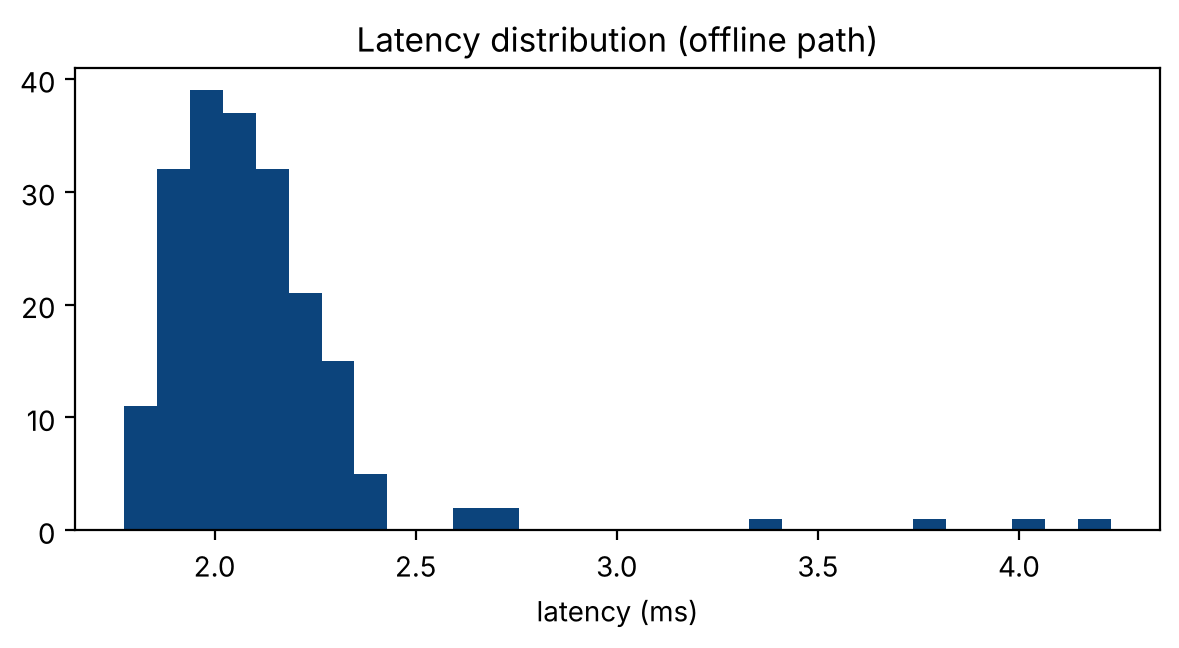

In [4]:
import time
from ad_rag.evaluation import load_golden

qs = [g["question"] for g in load_golden(ROOT / "data/eval/golden_set.jsonl") if g["category"] == "in_scope"]
lat = []
t_start = time.perf_counter()
for i in range(200):
    t0 = time.perf_counter()
    client.post("/ask", json={"question": qs[i % len(qs)]})        # cycle through real questions
    lat.append(time.perf_counter() - t0)
elapsed = time.perf_counter() - t_start

lat_ms = np.array(lat) * 1000
print(f"requests: {len(lat)} | throughput: {len(lat) / elapsed:.0f} req/s | p50 {np.percentile(lat_ms, 50):.1f} ms | p95 {np.percentile(lat_ms, 95):.1f} ms")
plt.figure(figsize=(7, 3)); plt.hist(lat_ms, bins=30, color="#0C447C"); plt.xlabel("latency (ms)"); plt.title("Latency distribution (offline path)"); plt.show()

### Step 4: Metrics for dashboards and alerts

**Rationale.** Prometheus scrapes `/metrics` and Grafana or Alertmanager act on it. We expose request counts by outcome, latency histograms, agent escalations and feedback counts. The summary endpoint adds drift status.

**How this step is evaluated.** Counters match the traffic we generated; histograms have buckets; drift block is present.

In [5]:
print(client.get("/metrics").text[:900])
print("...\nsummary:", json.dumps(client.get("/metrics/summary").json(), indent=1)[:700])

agent_requests_total{escalated="false"} 1.0
feedback_total{helpful="true"} 1.0
rag_requests_total{status="answered"} 202.0
agent_request_seconds_bucket{le="0.01"} 1
agent_request_seconds_bucket{le="0.05"} 1
agent_request_seconds_bucket{le="0.1"} 1
agent_request_seconds_bucket{le="0.25"} 1
agent_request_seconds_bucket{le="0.5"} 1
agent_request_seconds_bucket{le="1"} 1
agent_request_seconds_bucket{le="2.5"} 1
agent_request_seconds_bucket{le="5"} 1
agent_request_seconds_bucket{le="10"} 1
agent_request_seconds_bucket{le="+Inf"} 1
agent_request_seconds_sum 0.002390922999893519
agent_request_seconds_count 1
rag_request_seconds_bucket{le="0.01"} 201
rag_request_seconds_bucket{le="0.05"} 202
rag_request_seconds_bucket{le="0.1"} 202
rag_request_seconds_bucket{le="0.25"} 202
rag_request_seconds_bucket{le="0.5"} 202
rag_request_seconds_bucket{le="1"} 202
rag_request_seconds_bucket{le="2.5"} 202
rag
...
summary: {
 "counters": {
  "rag_requests_total{status=\"answered\"}": 202.0,
  "agent_requests

### Step 5: Drift monitoring: simulate a shift in what users ask

**Rationale.** Models rarely fail at launch; they decay as usage shifts (new drugs, new guidelines, a new user group). Two cheap early-warning signals: the **ungrounded rate** (questions the corpus cannot answer) and the **mean best retrieval score**. We replay 60 normal questions followed by 60 off-topic ones and watch the alerts fire.

**How this step is evaluated.** Alerts must stay silent during normal traffic and fire after the shift. The remedy is a corpus refresh and re-indexing (and a review of whether scope should expand).

first alert at request # 70 | alerts now: ['ungrounded_rate 1.00 > 0.25', 'mean_best_score 0.080 dropped >15% vs baseline 0.318']


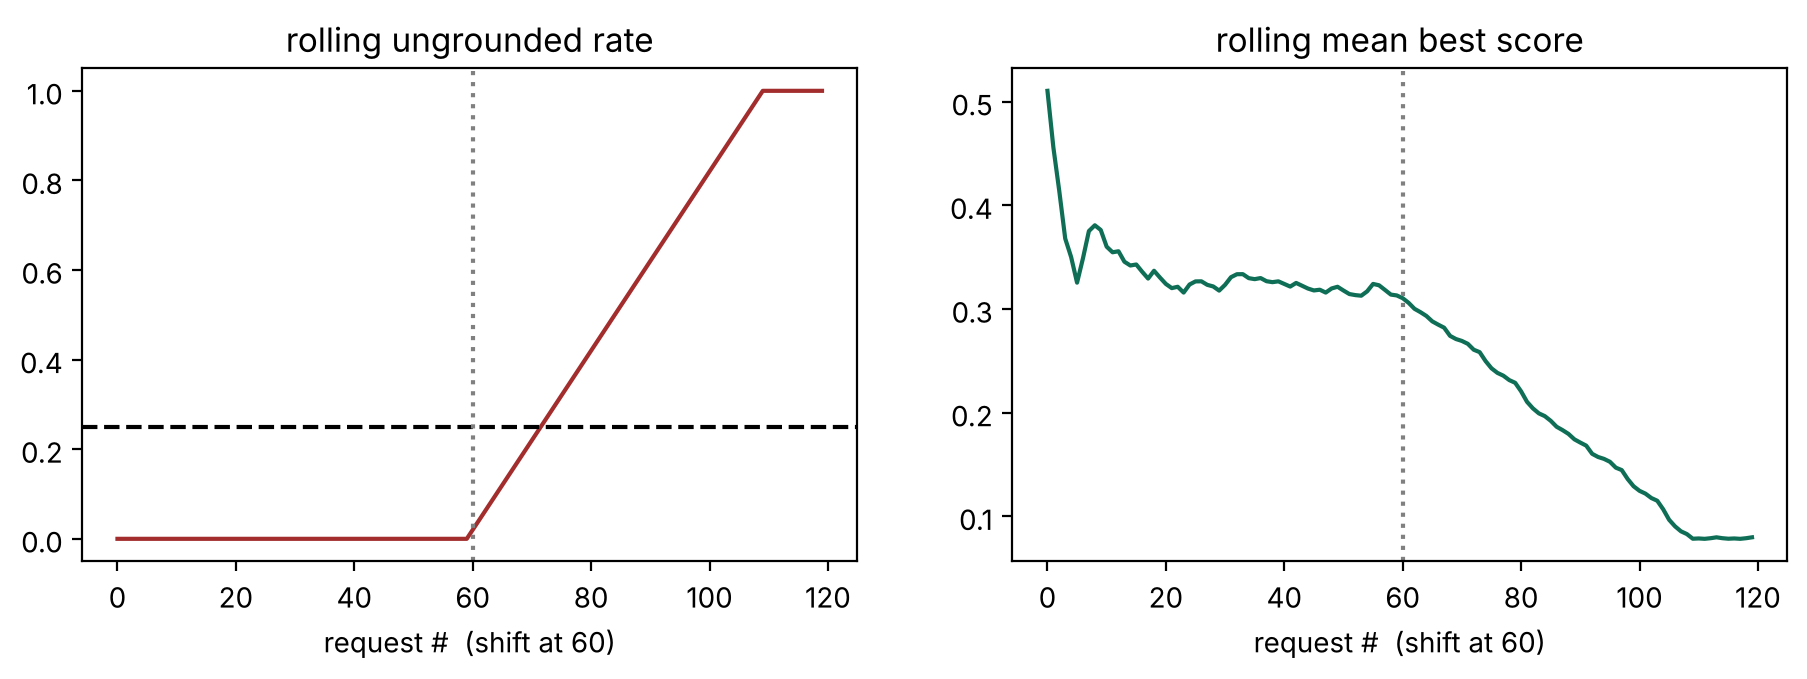

In [6]:
from ad_rag.monitoring import DriftMonitor

normal = qs
shifted = ["How do I file taxes as a freelancer?", "What is the best laptop for gaming?", "Explain quantum entanglement",
           "Recipe for sourdough bread", "Who won the world cup in 2010?", "How do I train a puppy?"]

mon = DriftMonitor(window=50, ungrounded_rate_alert=0.25, score_drop_alert=0.15)
history = []
for i in range(120):
    q = normal[i % len(normal)] if i < 60 else shifted[i % len(shifted)]
    r = pipe.ask(q)
    mon.record(r.metrics.get("best_score", 0.0), r.grounded)
    if i == 29:
        mon.set_baseline(float(np.mean(mon.scores)))            # baseline from the first healthy 30 requests
    st = mon.status()
    history.append({"i": i, "ungrounded": st.get("ungrounded_rate", 0), "mean_score": st.get("mean_best_score", 0), "alert": bool(st["alerts"])})
h = pd.DataFrame(history)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(h.i, h.ungrounded, color="#A32D2D"); ax[0].axhline(0.25, ls="--", color="black"); ax[0].set_title("rolling ungrounded rate")
ax[1].plot(h.i, h.mean_score, color="#0F6E56"); ax[1].set_title("rolling mean best score")
for a in ax:
    a.axvline(60, color="gray", ls=":"); a.set_xlabel("request #  (shift at 60)")
first_alert = h[h.alert].i.min()
print("first alert at request #", first_alert, "| alerts now:", mon.status()["alerts"]); plt.show()
assert not h[h.i < 60].alert.any() and first_alert > 60

### Step 6: Verify the audit trail

**Rationale.** Every request, tool call and feedback event is in a hash-chained log with redacted text only. Before an audit or incident review, verify the chain.

**How this step is evaluated.** `verify` returns OK; no raw PHI strings appear in the log.

In [7]:
from ad_rag.monitoring import AuditLog

# Send a question containing synthetic PHI, then prove it never reaches the log.
client.post("/ask", json={"question": "Is triage testing appropriate? Patient: Jane Doe SSN 123-45-6789"})
log_text = settings.path("audit_log").read_text()
print("chain:", AuditLog.verify(settings.path("audit_log")))
assert "123-45-6789" not in log_text and "Jane Doe" not in log_text
print("No raw PHI found in", len(log_text.splitlines()), "audit records.")

chain: (True, 443, None)
No raw PHI found in 443 audit records.


## Step 7: Containerise and run (commands, run in a terminal)

**Rationale.** A container pins Python, dependencies and code so the service behaves identically on a laptop, in CI and in
production; staged rollout and instant rollback become image-tag changes.
**How evaluated.** Container healthcheck passes, `scripts/smoke_test_api.sh` passes against it, and the CI pipeline builds the image.

```bash
# Build and run the API (offline mode, no keys needed)
docker build -t ad-rag:0.1.0 .
docker run --rm -p 8000:8000 ad-rag:0.1.0
bash scripts/smoke_test_api.sh http://localhost:8000

# Full stack: API + Prometheus (+ Jupyter profile)
docker compose up --build
docker compose --profile notebooks up            # adds JupyterLab on :8888

# Production-quality models: pass keys at runtime, never bake them into the image
docker run --rm -p 8000:8000 -e AD_RAG_LLM_BACKEND=anthropic -e ANTHROPIC_API_KEY=$ANTHROPIC_API_KEY \
           -e API_KEY=change-me ad-rag:0.1.0
```

## Release checklist (mirrors `.github/workflows/ci.yml`)

| Gate | Evidence |
|---|---|
| Unit and integration tests | `pytest` green |
| Golden-set regression gate | `scripts/run_eval.py` exits 0 |
| Notebook smoke test | notebooks execute end-to-end |
| Container build + healthcheck | `docker build`, `/health` returns ok |
| Rollback rehearsed | previous image tag redeployed |
| Monitoring verified | alert fired on simulated drift (Step 5) |
| Governance sign-off | model card and system card updated, review board approval |

**Next:** `07_langchain_langsmith_optional.ipynb` shows the same pipeline in LangChain with LangSmith tracing.